# Unit 4 · Natural Language & Conversational Visualization — Case-Based Activity
**Case:** *Auditing ChatViz at RideNow*

RideNow is a ride-hailing company. Its operations team has piloted **ChatViz**, a chat assistant that turns plain-language questions into charts and lets analysts keep refining them in conversation.
Before it goes to every analyst, you have been asked to **audit** it: how it reads a question, how it handles follow-ups, how it generates and validates chart specifications, how it edits charts, and what goes wrong.

**How to work**
* Run the cells from top to bottom. Do **not** edit the setup cell.
* Wherever you see `# TODO`, replace the placeholder (`None` or `""`) with your answer or code.
* Written answers: two or three sentences, using ideas from the lecture.

In [1]:
import math, re, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

warnings.filterwarnings("ignore")
plt.rcParams.update({"figure.dpi": 100, "axes.spines.top": False, "axes.spines.right": False, "axes.titlesize": 10, "axes.titleweight": "bold"})
pd.set_option("display.max_columns", 20, "display.width", 140, "display.max_colwidth", 90)

In [2]:
# ---------------- mini Vega-Lite-style renderer (do not edit) ----------------
import copy, json, difflib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

MONTHS = ["Jan", "Feb", "Mar", "Apr", "May", "Jun", "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"]
ACCENT, GREY, BLUE = "#E8710A", "#BDBDBD", "#4C72B0"

def apply_filters(df, spec):
    for t in spec.get("transform", []):
        f = t.get("filter")
        if not f:
            continue
        if "equal" in f:
            df = df[df[f["field"]] == f["equal"]]
        elif "oneOf" in f:
            df = df[df[f["field"]].isin(f["oneOf"])]
    return df

def is_horizontal(spec):
    e = spec["encoding"]
    return spec["mark"] == "bar" and e["x"].get("type") == "quantitative" and e["y"].get("type") in ("nominal", "ordinal")

def compute(spec, df):
    """Return the tidy table that the chart plots (used for drawing AND for checking values)."""
    enc, mark = spec["encoding"], spec["mark"]
    d = apply_filters(df, spec)
    x, y, c = enc["x"], enc["y"], enc.get("color", {})
    sf = c.get("field")
    if mark == "point":
        return d[[x["field"], y["field"]] + ([sf] if sf else [])].copy()
    if x.get("bin"):
        return d[[x["field"]]].copy()
    cat, val = (y, x) if is_horizontal(spec) else (x, y)
    agg = val.get("aggregate", "mean")
    keys = [cat["field"]] + ([sf] if sf else [])
    out = d.groupby(keys).size().rename("value") if agg == "count" else d.groupby(keys)[val["field"]].agg(agg).rename("value")
    return out.reset_index()

def _order(labels, field, sort, totals):
    labels = list(dict.fromkeys(labels))
    if sort in ("-y", "-x"):
        return sorted(labels, key=lambda l: -totals[l])
    if sort in ("y", "x"):
        return sorted(labels, key=lambda l: totals[l])
    if field == "month":
        return sorted(labels, key=MONTHS.index)
    return sorted(labels)

def render_spec(spec, df, ax=None, figsize=(6, 3.4)):
    enc, mark = spec["encoding"], spec["mark"]
    if ax is None:
        _, ax = plt.subplots(figsize=figsize)
    t = compute(spec, df)
    x, y, c = enc["x"], enc["y"], enc.get("color", {})
    sf = c.get("field")
    if mark == "point":
        if sf:
            for k, g in t.groupby(sf):
                ax.scatter(g[x["field"]], g[y["field"]], s=10, alpha=.6, label=str(k))
            ax.legend(fontsize=7, title=sf, title_fontsize=7)
        else:
            ax.scatter(t[x["field"]], t[y["field"]], s=10, alpha=.5, color=BLUE)
        ax.set_xlabel(x.get("title", x["field"])); ax.set_ylabel(y.get("title", y["field"]))
    elif x.get("bin"):
        ax.hist(t[x["field"]], bins=25, color=BLUE)
        ax.set_xlabel(x.get("title", x["field"])); ax.set_ylabel(y.get("title", "count"))
    else:
        horiz = is_horizontal(spec)
        cat, val = (y, x) if horiz else (x, y)
        cf = cat["field"]
        tot = t.groupby(cf)["value"].sum()
        labels = _order(t[cf], cf, cat.get("sort"), tot)
        idx = np.arange(len(labels))
        series = sorted(t[sf].unique()) if sf else [None]
        for j, s in enumerate(series):
            g = t if s is None else t[t[sf] == s]
            vals = g.set_index(cf)["value"].reindex(labels).values
            if mark == "bar":
                w = 0.8 / len(series)
                pos = idx + (j - (len(series) - 1) / 2) * w
                colors = BLUE
                cond = c.get("condition")
                if s is None and cond:
                    colors = [ACCENT if l == cond["equal"] else c.get("value", GREY) for l in labels]
                (ax.barh if horiz else ax.bar)(pos, vals, w * 0.95, color=colors, label=None if s is None else str(s))
            else:
                ax.plot(idx, vals, marker="o", ms=3, label=None if s is None else str(s))
        (ax.set_yticks if horiz else ax.set_xticks)(idx)
        (ax.set_yticklabels if horiz else ax.set_xticklabels)(labels, fontsize=8)
        if horiz: ax.invert_yaxis()
        vtitle = val.get("title") or f"{val.get('aggregate', 'mean')}({val['field']})"
        ctitle = cat.get("title") or cat["field"]
        (ax.set_ylabel if not horiz else ax.set_xlabel)(vtitle)
        (ax.set_xlabel if not horiz else ax.set_ylabel)(ctitle)
        sc = val.get("scale", {})
        if sc.get("type") == "log":
            (ax.set_xscale if horiz else ax.set_yscale)("log")
        if mark == "bar" and sc.get("zero") is False:
            lo = t["value"].min() * 0.96
            (ax.set_xlim if horiz else ax.set_ylim)(lo, t["value"].max() * 1.02)
        if sf:
            ax.legend(fontsize=7, title=sf, title_fontsize=7)
    ax.set_title(spec.get("title", ""), fontsize=10, fontweight="bold", loc="left")
    return ax

def show_specs(specs, df, ncols=3, w=4.6, h=3.3):
    n = len(specs); nrows = -(-n // ncols)
    fig, axes = plt.subplots(nrows, ncols, figsize=(w * ncols, h * nrows), squeeze=False)
    for ax in axes.ravel(): ax.axis("off")
    for ax, s in zip(axes.ravel(), specs):
        ax.axis("on"); render_spec(s, df, ax=ax)
    plt.tight_layout(); plt.show()

In [3]:
# ---------------- synthetic RideNow trips (do not edit) ----------------
rng = np.random.default_rng(21)
n = 1200
city = rng.choice(["Bengaluru", "Hyderabad", "Chennai", "Pune"], n, p=[.38, .27, .20, .15])
vehicle = rng.choice(["Auto", "Mini", "Sedan", "Bike"], n, p=[.30, .35, .20, .15])
year = rng.choice([2024, 2025], n)
month = rng.choice(MONTHS, n)
distance = np.clip(rng.gamma(2.4, 2.6, n), 0.8, 30).round(1)
mult = {"Auto": 9, "Mini": 11, "Sedan": 14, "Bike": 6}
city_f = {"Bengaluru": 1.10, "Hyderabad": 1.00, "Chennai": 0.95, "Pune": 1.05}
fare = (35 + distance * np.array([mult[v] for v in vehicle]) * np.array([city_f[c] for c in city]) * rng.normal(1, .06, n)).round(0)
wait = np.clip(rng.gamma(2.2, 2.0, n) + (city == "Bengaluru") * 2.5, 0.5, None).round(1)
cancel_p = np.clip(0.03 + 0.004 * wait + (city == "Chennai") * 0.012 - (city == "Pune") * 0.01, 0.005, None)

df = pd.DataFrame({
    "city": city, "year": year, "month": month, "vehicle_type": vehicle, "distance_km": distance, "fare": fare, "wait_min": wait,
    "driver_rating": np.clip(rng.normal(4.4, .35, n) - 0.02 * wait, 1, 5).round(1),
    "payment_mode": rng.choice(["UPI", "Cash", "Card", "Wallet"], n, p=[.55, .20, .15, .10]),
    "cancelled": (rng.random(n) < cancel_p).astype(int),
})

# helpers used later (do not edit)
def spec_diff(a, b):
    def flat(d, p=""):
        out = {}
        for k, v in d.items():
            q = f"{p}.{k}" if p else k
            out.update(flat(v, q) if isinstance(v, dict) else {q: str(v)})
        return out
    fa, fb = flat(a), flat(b)
    return sorted(k for k in set(fa) | set(fb) if fa.get(k) != fb.get(k))

def lint_chart(spec):
    issues, t = [], spec.get("title", "").strip().lower()
    if not t: issues.append("no title")
    if re.match(r"^(this|the) (chart|figure|graph|plot) (shows|displays|presents)", t): issues.append("title describes the chart instead of asserting the point")
    for ch in ("x", "y"):
        e = spec["encoding"].get(ch, {})
        if e.get("type") == "quantitative" and "title" not in e: issues.append(f"{ch}-axis has no title with units")
    return issues or ["OK"]

df.head()

,city,year,month,vehicle_type,distance_km,fare,wait_min,driver_rating,payment_mode,cancelled
0,Chennai,2025,Sep,Bike,4.8,59.0,2.3,5.0,UPI,0
1,Hyderabad,2024,Aug,Auto,9.9,122.0,4.7,4.5,Card,0
2,Chennai,2025,Aug,Mini,3.1,65.0,8.1,4.0,UPI,0
3,Bengaluru,2024,Sep,Mini,2.6,64.0,6.5,4.8,UPI,0
4,Hyderabad,2024,Sep,Mini,3.5,77.0,3.0,4.7,Cash,0


---
## Case 1 · How does ChatViz *read* a question? (NL2Vis, query → task abstraction, semantic parsing, ambiguity)
### 1a · From words to abstract tasks
Seven questions came in on the first day. For each one, name the **abstract task** ChatViz should infer.
Use exactly one of: `"trend"`, `"compare"`, `"extremes"`, `"distribution"`, `"correlation"`, `"part-to-whole"`, `"outliers"`.

In [4]:
questions = {
    "Q1": "How did the number of rides change month by month in 2025?",
    "Q2": "Compare average fare across cities",
    "Q3": "Does fare depend on distance?",
    "Q4": "Which 2 cities had the highest cancellation rate?",
    "Q5": "How spread out are the driver ratings?",
    "Q6": "What percentage of rides are paid by UPI?",
    "Q7": "Compare auto and sedan fares over the last 2 years",
}
TASKS = ["trend", "compare", "extremes", "distribution", "correlation", "part-to-whole", "outliers"]
DEFAULT_CHART = {"trend": "line chart", "compare": "sorted bar chart", "extremes": "sorted bar, top-k highlighted", "distribution": "histogram / boxplot",
                 "correlation": "scatter plot", "part-to-whole": "stacked bar (few parts)", "outliers": "scatter / line with highlights"}
pd.Series(questions, name="question").to_frame()

,question
Q1,How did the number of rides change month by month in 2025?
Q2,Compare average fare across cities
Q3,Does fare depend on distance?
Q4,Which 2 cities had the highest cancellation rate?
Q5,How spread out are the driver ratings?
Q6,What percentage of rides are paid by UPI?
Q7,Compare auto and sedan fares over the last 2 years


In [5]:
abstract_tasks = {
    "Q1": "trend",   # TODO
    "Q2": "compare",   # TODO
    "Q3": "correlation",   # TODO
    "Q4": "extremes",   # TODO
    "Q5": "distribution",   # TODO
    "Q6": "part-to-whole",   # TODO
    "Q7": "trend",   # TODO  (hint: when two cues compete, which one dominates?)
}
assert all(v in TASKS for v in abstract_tasks.values()), "Choose each answer from TASKS"
pd.DataFrame({"question": questions, "your task": abstract_tasks}).assign(chart=lambda d: d["your task"].map(DEFAULT_CHART))

,question,your task,chart
Q1,How did the number of rides change month by month in 2025?,trend,line chart
Q2,Compare average fare across cities,compare,sorted bar chart
Q3,Does fare depend on distance?,correlation,scatter plot
Q4,Which 2 cities had the highest cancellation rate?,extremes,"sorted bar, top-k highlighted"
Q5,How spread out are the driver ratings?,distribution,histogram / boxplot
Q6,What percentage of rides are paid by UPI?,part-to-whole,stacked bar (few parts)
Q7,Compare auto and sedan fares over the last 2 years,trend,line chart


### 1b · Typos in attribute names
A user typed *"show avg **distnce** by city"*. ChatViz matches a word to a column using **similarity = 1 − d / max(len(a), len(b))**, where *d* is the Levenshtein distance,
and accepts the best match only if it is **≥ 0.7**; otherwise it must **ask, not guess**. The Levenshtein function is given; write `similarity` and `match_column`.

In [6]:
def levenshtein(a, b):
    prev = list(range(len(b) + 1))
    for i, ca in enumerate(a, 1):
        cur = [i]
        for j, cb in enumerate(b, 1):
            cur.append(min(prev[j] + 1, cur[j - 1] + 1, prev[j - 1] + (ca != cb)))
        prev = cur
    return prev[-1]

known_columns = ["distance", "duration", "discount", "driver", "fare"]

In [7]:
def similarity(a, b):
    # TODO: 1 - d / max(len(a), len(b))
    a, b = a.lower(), b.lower()
    if max(len(a), len(b)) == 0:
        return 1.0
    return 1 - levenshtein(a, b) / max(len(a), len(b))


def match_column(token, columns, threshold=0.7):
    # TODO: return the best-matching column if its similarity >= threshold, otherwise None
    scores = {col: similarity(token, col) for col in columns}
    best = max(scores, key=scores.get)
    return best if scores[best] >= threshold else None

for tok in ["distnce", "fre", "zzzz"]:
    print(f"{tok!r:10} -> {match_column(tok, known_columns)}")

assert match_column("distnce", known_columns) == "distance"
assert match_column("fre", known_columns) == "fare"
assert match_column("zzzz", known_columns) is None, "no column passes the threshold: ask the user"

'distnce'  -> distance
'fre'      -> fare
'zzzz'     -> None


### 1c · Handling ambiguity
ChatViz can resolve an ambiguous query in three ways: `"default + show interpretation"`, `"ambiguity widget"`, or `"clarifying question"`.
Pick the **best-fitting** strategy for each situation.

* **S1.** An analyst is exploring casually and types *"show fare"*. The table has `base_fare` and `total_fare`. A wrong guess costs nothing and she wants speed.
* **S2.** A manager types *"top rides"* and three things are unclear at once: **top by what** (fare / distance), **sum or average**, and **which year**. He can see the screen.
* **S3.** A chart for a regulator's filing is requested: *"average fare"*, and there is exactly **one** doubt: `fare` vs `fare_after_discount`. A wrong guess here is costly.

### Reflection: interpreting natural-language requests

Answer each question in two or three sentences, using ideas from the lecture and evidence from your work.

1. Which words or phrases in a user's question are most important for identifying the intended measure, dimensions, filters, and chart type? Explain why.

2. How should ChatViz respond when a user's request is ambiguous in more than one way? Give an example of a useful clarifying question.

3. How could different analysts interpret the same natural-language request differently? What design choices could make ChatViz's behavior more consistent?


**Answers**

1. Key words. Aggregation and measure words ("average", "total", "rate", "number of rides") name the measure; "by", "across" and "per" mark the dimensions ("by city"); values and time phrases ("in 2025", "only Bengaluru") become filters; and task verbs ("change month by month", "compare", "highest", "spread", "percentage", "depend on") tell ChatViz the abstract task, which decides the chart type. They matter because each one maps onto a different slot of the spec. In 1a, the same field (fare) produced a bar chart, a scatter plot or a line depending only on these task words.

2. Multiple ambiguities. When a request is ambiguous in several ways, ChatViz should not fire off a chain of questions or silently guess everything. It should draw a sensible default and show an ambiguity widget (dropdowns for each unclear choice), as for S2 "top rides". If one choice is high-stakes, it should ask one focused clarifying question first, for example: *"By 'top rides', do you mean the highest total fare, the highest average fare, or the longest distance, and for 2024, 2025 or both?"*

3. Different readings, more consistency. One analyst might read "top rides" as the highest total fare, another as the longest trips; one might read "fare" as `base_fare`, another as `total_fare`; and some assume "this year" while others assume all years. To make behaviour consistent, ChatViz can use a governed semantic layer (a glossary that fixes what "revenue" or "fare" means), apply documented defaults, and always echo its interpretation ("mean total_fare by city, all years"). Deterministic decoding with fixed few-shot examples also makes the same question give the same chart.

In [8]:
ambiguity_strategy = {
    "S1": "default + show interpretation",   # TODO
    "S2": "ambiguity widget",   # TODO
    "S3": "clarifying question",   # TODO
}
STRATEGIES = {"default + show interpretation", "ambiguity widget", "clarifying question"}
assert all(v in STRATEGIES for v in ambiguity_strategy.values()), "Use one of the three strategy names"

---
## Case 2 · Conversations (conversational systems, multi-turn refinement, follow-ups and context)
ChatViz keeps a **dialogue state**: the measure, aggregation, x field, colour field, filters and mark.
### 2a · Name the turn
For each utterance (said *after* a chart of mean fare by city), name the **turn type**, choosing from `TURN_TYPES`.
Then, for three follow-ups said after *"fares in Chennai in 2025"*, name the **context transition**: `"Continue"`, `"Retain"` or `"Shift"`.

In [9]:
TURN_TYPES = ["Refine (filter)", "Elaborate (add field)", "Change aggregation", "Change view", "Drill down", "Compare", "Shift / reset"]
utterances = {
    "U1": "only for Bengaluru and Pune",
    "U2": "split it by vehicle type",
    "U3": "show the median instead",
    "U4": "as a line chart",
    "U5": "and how does that compare with 2024?",
    "U6": "now show driver ratings by city",
}
follow_ups = {
    "T1": "by vehicle type",
    "T2": "what about wait times?",
    "T3": "show cancellations by city",
}
display(pd.Series(utterances, name="utterance").to_frame()); display(pd.Series(follow_ups, name="follow-up").to_frame())

,utterance
U1,only for Bengaluru and Pune
U2,split it by vehicle type
U3,show the median instead
U4,as a line chart
U5,and how does that compare with 2024?
U6,now show driver ratings by city


,follow-up
T1,by vehicle type
T2,what about wait times?
T3,show cancellations by city


In [10]:
turn_types = {
    "U1": "Refine (filter)",   # TODO
    "U2": "Elaborate (add field)",   # TODO
    "U3": "Change aggregation",   # TODO
    "U4": "Change view",   # TODO
    "U5": "Compare",   # TODO
    "U6": "Shift / reset",    # TODO
}
transitions = {
    "T1": "Continue",   # TODO  "Continue" / "Retain" / "Shift"
    "T2": "Retain",   # TODO
    "T3": "Shift",   # TODO
}
assert all(v in TURN_TYPES for v in turn_types.values()), "Choose from TURN_TYPES"
assert all(v in {"Continue", "Retain", "Shift"} for v in transitions.values()), "Use Continue, Retain or Shift"

### 2b · Update the dialogue state
Complete `apply_turn(state, turn, **kw)`. It must return a **new** state (never modify the old one) and only change the slot that the turn affects:

| `turn` | keyword | change |
|---|---|---|
| `"refine"` | `field`, `values` | set `filters[field] = values` |
| `"elaborate"` | `field` | `color = field` |
| `"change_agg"` | `agg` | `agg = agg` |
| `"change_view"` | `mark` | `mark = mark` |
| `"shift"` | `new_state` | return `new_state` (everything old is dropped) |

In [11]:
import copy

def apply_turn(state, turn, **kw):
    new = copy.deepcopy(state)
    # TODO: handle the five turn kinds from the table above and return `new`
    if turn == "refine":
        new["filters"][kw["field"]] = kw["values"]
    elif turn == "elaborate":
        new["color"] = kw["field"]
    elif turn == "change_agg":
        new["agg"] = kw["agg"]
    elif turn == "change_view":
        new["mark"] = kw["mark"]
    elif turn == "shift":
        return copy.deepcopy(kw["new_state"])   # everything old is dropped
    else:
        raise ValueError(f"unknown turn type: {turn}")
    return new

s0 = {"measure": "fare", "agg": "mean", "x": "city", "color": None, "filters": {}, "mark": "bar"}
s1 = apply_turn(s0, "refine", field="year", values=[2025])
s2 = apply_turn(s1, "refine", field="city", values=["Chennai", "Pune"])
s3 = apply_turn(s2, "elaborate", field="vehicle_type")
s4 = apply_turn(s3, "change_agg", agg="median")
s5 = apply_turn(s4, "change_view", mark="line")
s6 = apply_turn(s5, "shift", new_state={"measure": "driver_rating", "agg": "mean", "x": "city", "color": None, "filters": {}, "mark": "bar"})
for i, s in enumerate([s0, s1, s2, s3, s4, s5, s6]): print(i, s)

assert s0["filters"] == {}, "apply_turn must not modify the old state"
assert s2["filters"] == {"year": [2025], "city": ["Chennai", "Pune"]}, "earlier filters must be inherited"
assert s5["agg"] == "median" and s5["color"] == "vehicle_type" and s5["mark"] == "line" and s5["measure"] == "fare"
assert s6["filters"] == {} and s6["measure"] == "driver_rating", "a shift must reset everything"

0 {'measure': 'fare', 'agg': 'mean', 'x': 'city', 'color': None, 'filters': {}, 'mark': 'bar'}
1 {'measure': 'fare', 'agg': 'mean', 'x': 'city', 'color': None, 'filters': {'year': [2025]}, 'mark': 'bar'}
2 {'measure': 'fare', 'agg': 'mean', 'x': 'city', 'color': None, 'filters': {'year': [2025], 'city': ['Chennai', 'Pune']}, 'mark': 'bar'}
3 {'measure': 'fare', 'agg': 'mean', 'x': 'city', 'color': 'vehicle_type', 'filters': {'year': [2025], 'city': ['Chennai', 'Pune']}, 'mark': 'bar'}
4 {'measure': 'fare', 'agg': 'median', 'x': 'city', 'color': 'vehicle_type', 'filters': {'year': [2025], 'city': ['Chennai', 'Pune']}, 'mark': 'bar'}
5 {'measure': 'fare', 'agg': 'median', 'x': 'city', 'color': 'vehicle_type', 'filters': {'year': [2025], 'city': ['Chennai', 'Pune']}, 'mark': 'line'}
6 {'measure': 'driver_rating', 'agg': 'mean', 'x': 'city', 'color': None, 'filters': {}, 'mark': 'bar'}


### 2c · Why long conversations are fragile
ChatViz resolves each dependent follow-up correctly with probability **p = 0.92**, and every turn builds on the previous one, so the chance that a whole session is correct is **pⁿ**.
Compute: (1) the chance a **6-turn** session is fully correct; (2) the same after an upgrade to **p = 0.97**; (3) the smallest number of turns after which the chance falls **below 0.5** at p = 0.92.

### Reflection: conversational context and follow-ups

4. What information from the previous turn must ChatViz preserve when a user says, ?Now show that by region?? What could go wrong if it does not preserve that context?

5. When should a follow-up request be interpreted as a modification of the current chart rather than as a new visualization request?

6. How would you test whether ChatViz handles pronouns and references such as ?that,? ?those,? or ?the same trend? correctly across several turns?


**Answers**

4. Context for "Now show that by region". "That" points at the current measure and aggregation (e.g. mean fare), so ChatViz must keep the measure, aggregation, all active filters (e.g. year = 2025, vehicle = Sedan) and usually the mark, and only replace or add the grouping field. If it drops the context, it may chart the wrong measure or quietly drop the filters and show all years, which is exactly incident I2. The new chart would look plausible but would answer a different question.

5. Modify vs. new chart. A follow-up should be treated as an edit when it is incomplete on its own and depends on the current chart. Typical signs are anaphora ("that", "it", "those"), fragments ("by vehicle type", "only Pune", "as a line"), and edit verbs ("sort", "highlight", "instead"). It should be treated as a new request (a Shift) when it names a new measure and full scope that stand alone, like "now show driver ratings by city". If the case is unclear, ChatViz should use Retain (keep filters, swap the measure) and echo that the filters were kept.

6. Testing references. I would build scripted multi-turn test dialogues with a known gold dialogue state after every turn. For example: "mean fare by city" → "only 2025" → "split that by vehicle type" → "show those as a line" → "does the same trend hold for wait time?" After each turn, I would assert the spec slots (measure, aggregation, filters, colour, mark) against the gold state, not just whether the chart rendered. I would also include adversarial cases (a pronoun after a topic shift, "those" referring to a filtered subset) and report per-turn accuracy, since errors compound as pⁿ (0.92⁶ ≈ 0.61).


In [13]:
p = 0.92
session_6_turns  = p ** 6   # TODO
session_6_better = 0.97 ** 6   # TODO (p = 0.97)
turns_below_half = math.ceil(math.log(0.5) / math.log(p))   # TODO (an integer)
assert p ** turns_below_half < 0.5 <= p ** (turns_below_half - 1)

print(round(session_6_turns, 4), round(session_6_better, 4), turns_below_half)

0.6064 0.833 9


---
## Case 3 · ChatViz's text-to-chart engine (prompting strategies, generate → execute → repair)
### 3a · Fix the prompt
Five problems were reported. Match each to the **prompting strategy** that targets it, using exactly one of:
`"Zero-shot"`, `"Few-shot"`, `"Schema + samples"`, `"Plan, then code"`, `"Design rules"`, `"Self-repair loop"`.

* **P1.** The model keeps plotting columns such as `avg_fare` that don't exist.
* **P2.** Different runs return code in different styles, and a downstream tool needs one fixed output format.
* **P3.** Analysts want to read the reasoning (fields, aggregation, chart) *before* any code runs.
* **P4.** Generated charts keep using 3-D pies and unlabelled axes.
* **P5.** The code sometimes crashes on a mistyped column name, and users should never see that.

In [14]:
prompt_fix = {
    "P1": "Schema + samples",   # TODO
    "P2": "Few-shot",   # TODO
    "P3": "Plan, then code",   # TODO
    "P4": "Design rules",   # TODO
    "P5": "Self-repair loop",   # TODO
}
STRATS = {"Zero-shot", "Few-shot", "Schema + samples", "Plan, then code", "Design rules", "Self-repair loop"}
assert all(v in STRATS for v in prompt_fix.values()), "Use one of the six strategy names"

### 3b · The Generate → Execute → Repair loop
Finish `generate_execute_repair`: generate code, execute it, and **on error send the error + schema back** to the LLM (`build_repair_prompt`). Allow at most `max_tries` attempts.
If every attempt fails, return `(None, max_tries)` so the interface can **ask the user** instead of showing garbage. On success return `(code, attempt_number)`.

### Reflection: generating, executing, and repairing charts

7. What should ChatViz do when the requested field does not exist, has an unexpected type, or contains too many missing values?

8. Which errors should ChatViz explain to the analyst, and which implementation details can remain hidden? Justify your boundary between helpful transparency and unnecessary technical detail.

9. How could an apparently valid chart still mislead an analyst? Discuss one issue involving aggregation, scale, missing data, or the choice of visual encoding.

**Answers**

7. Missing field, wrong type, many missing values. If the field does not exist, ChatViz should try fuzzy matching (as in 1b) and use the match only if it is close enough. Otherwise it should ask the user and list similar real columns, never invent data like the `driver_score` case (I3). If the type is unexpected (e.g. a numeric ID or text-coded numbers), it should cast or re-type the field and say so, or pick a suitable encoding. If too many values are missing, it should warn ("38% of wait_min is missing; 412 rows excluded"), show the count, and offer to exclude or impute rather than plotting silently.

8. What to explain vs. hide. ChatViz should explain anything that changes the meaning of the answer: the interpretation used, fields that were substituted or not found, dropped filters, excluded rows, missing data, and when it gave up after repair attempts. Stack traces, retry counts, prompt text and internal repair steps can stay hidden, but available on request through "show spec / code". The boundary is: if the analyst would draw a different conclusion by knowing it, show it; if it is only how ChatViz got there, hide it.

9. Valid but misleading chart. A chart can be technically correct and still mislead. A sum-versus-mean mix-up is one example (I1): Bengaluru wins on totals only because it has the most rides. Another is a bar axis starting at 4% (I5), which makes 4.4% look twice as bad as 4.1%. Averages over small groups can also hide large uncertainty, so a city with 30 rides looks as reliable as one with 450. Every one of these runs without error, which is why validation must check meaning, not just execution.


In [15]:
import difflib

TEMPLATE = "fig, ax = plt.subplots(figsize=(5, 3))\nt = df.groupby('city')['{col}'].mean()\nax.bar(t.index, t.values)\nax.set_title('Mean {col} by city')"

def build_prompt(question, df):
    return f"Write matplotlib code using DataFrame df.\nColumns: {', '.join(df.columns)}\nQuestion: {question}"

def build_repair_prompt(question, df, error):
    return build_prompt(question, df) + f"\nERROR: {error}\nFix the code. Only use the columns listed above."

def fake_llm(prompt):                                   # a stand-in for the real LLM
    if "ERROR:" in prompt:
        m = re.search(r"Column not found: (\w+)", prompt)
        cols = re.search(r"Columns: (.*)", prompt).group(1).split(", ")
        fix = difflib.get_close_matches(m.group(1) if m else "", cols, n=1, cutoff=0.6)
        return TEMPLATE.format(col=fix[0]) if fix else "raise ValueError('no matching column')"
    q = prompt.split("Question:")[1].lower()
    if "happiness" in q: return TEMPLATE.format(col="happiness")      # invented column
    return TEMPLATE.format(col="far")                                  # typo for 'fare'

def execute(code_str, df):
    try:
        exec(code_str, {"df": df, "pd": pd, "np": np, "plt": plt}); return None
    except Exception as e:
        return f"{type(e).__name__}: {e}"

attempt 1 failed -> KeyError: 'Column not found: far'


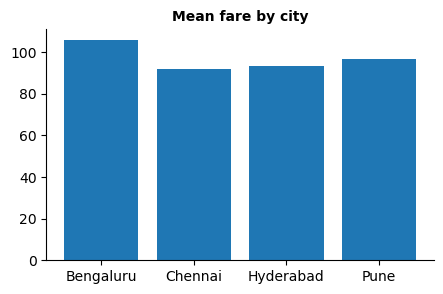

attempt 1 failed -> KeyError: 'Column not found: happiness'
attempt 2 failed -> ValueError: no matching column
attempt 3 failed -> ValueError: no matching column
question 1 -> success after 2 attempt(s)
question 2 -> ASK THE USER after 3 attempt(s)


In [16]:
def generate_execute_repair(question, df, llm, max_tries=3):
    prompt = build_prompt(question, df)
    for attempt in range(1, max_tries + 1):
        code_str = llm(prompt)
        err = execute(code_str, df)
        # TODO 1: if there is no error -> plt.show(), then return (code_str, attempt)
        # TODO 2: otherwise close the figure (plt.close("all")) and build the next prompt with build_repair_prompt(...)
    # TODO 3: every attempt failed -> return (None, max_tries)
        if err is None:                       # success: show the chart and stop
            plt.show()
            return code_str, attempt
        plt.close("all")                      # discard any half-drawn figure
        print(f"attempt {attempt} failed -> {err}")
        prompt = build_repair_prompt(question, df, err)   # send error + schema back
    return None, max_tries                    # give up: the interface should ask the user

code_ok, tries_ok = generate_execute_repair("average fare by city", df, fake_llm)
code_bad, tries_bad = generate_execute_repair("average customer happiness by city", df, fake_llm)
print("question 1 ->", "success" if code_ok else "failed", "after", tries_ok, "attempt(s)")
print("question 2 ->", "success" if code_bad else "ASK THE USER", "after", tries_bad, "attempt(s)")

assert code_ok is not None and tries_ok == 2, "the typo should be repaired on the second attempt"
assert code_bad is None and tries_bad == 3, "an invented column cannot be repaired: ask the user after 3 tries"

---
## Case 4 · Specs, not just code (Vega-Lite specs, validation, evaluation)
ChatViz can also return a **chart specification** (a Vega-Lite-style dictionary). The question was **"average fare by vehicle type in 2025, as a bar chart"**.
Four candidate specs came back from the LLM; one is correct.

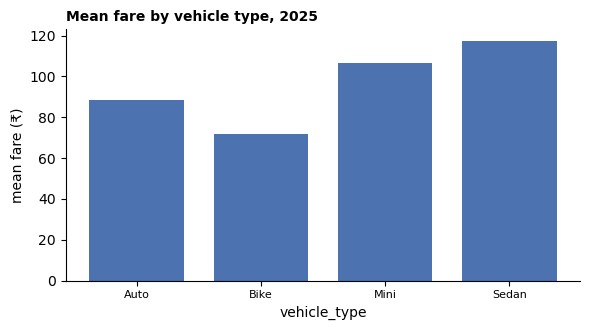

In [17]:
intent = {"aggregate": "mean", "filters": {"year": [2025]}}

good = {"title": "Mean fare by vehicle type, 2025", "transform": [{"filter": {"field": "year", "equal": 2025}}], "mark": "bar",
        "encoding": {"x": {"field": "vehicle_type", "type": "nominal"},
                     "y": {"field": "fare", "aggregate": "mean", "type": "quantitative", "title": "mean fare (₹)"}}}

import copy as _copy
B1 = _copy.deepcopy(good); B1["encoding"]["colour"] = {"field": "city", "type": "nominal"}                                     # key typo
B2 = _copy.deepcopy(good); B2["encoding"]["y"]["field"] = "fare_amount"                                                         # invented field
B3 = _copy.deepcopy(good); B3["encoding"]["shape"] = {"field": "wait_min", "type": "quantitative"}                              # wrong channel
B4 = _copy.deepcopy(good); B4["transform"] = []; B4["encoding"]["y"]["aggregate"] = "sum"                                       # wrong aggregate + filter dropped
specs = {"good": good, "B1": B1, "B2": B2, "B3": B3, "B4": B4}
render_spec(good, df); plt.tight_layout(); plt.show()

### 4a · Write two of the four validation checks
The **schema** and **field** checks are written for you. Write the **type–channel** check (shape must not encode a quantitative field; size must not encode a nominal field)
and the **sanity** check (compare the spec with the user's `intent`: aggregation and filters). Each returns a list of problem strings (empty list = pass).

In [18]:
import difflib
VALID_TOP = {"title", "data", "transform", "mark", "encoding"}
VALID_CH  = {"x", "y", "color", "shape", "size"}
VALID_KEYS = {"field", "type", "aggregate", "sort", "scale", "title", "condition", "value", "bin"}

def check_schema(spec):
    out = [f"unknown key '{k}'" for k in spec if k not in VALID_TOP]
    for ch, e in spec["encoding"].items():
        if ch not in VALID_CH:
            m = difflib.get_close_matches(ch, VALID_CH, 1)
            out.append(f"unknown channel '{ch}'" + (f" (did you mean '{m[0]}'?)" if m else ""))
    return out

def check_field(spec, df):
    used = [e["field"] for e in spec["encoding"].values() if isinstance(e, dict) and "field" in e]
    used += [t["filter"]["field"] for t in spec.get("transform", []) if "filter" in t]
    return [f"field '{f}' is not in the dataset" for f in used if f not in df.columns]

In [19]:
def check_type_channel(spec):
    problems = []
    # TODO: for every channel in spec["encoding"]:
    #   - "shape" with type "quantitative"  -> add a problem string
    #   - "size"  with type "nominal"       -> add a problem string
    for ch, e in spec["encoding"].items():
        if not isinstance(e, dict):
            continue
        t = e.get("type")
        if ch == "shape" and t == "quantitative":
            problems.append(f"shape encodes quantitative field '{e.get('field')}' (shape is only for a few nominal categories)")
        if ch == "size" and t == "nominal":
            problems.append(f"size encodes nominal field '{e.get('field')}' (size implies order/magnitude)")
    return problems

def check_sanity(spec, intent):
    problems = []
    # TODO 1: if the y or x encoding has an "aggregate" that differs from intent["aggregate"] -> add a problem
    # TODO 2: for every field in intent["filters"], the spec must contain a transform filter on that field
    #         whose value is the same (use "equal" for a single value) -> otherwise add a problem
    enc = spec["encoding"]
    # 1) aggregation must match what the user asked for
    for ch in ("x", "y"):
        agg = enc.get(ch, {}).get("aggregate")
        if agg is not None and agg != intent["aggregate"]:
            problems.append(f"{ch} uses aggregate '{agg}' but the user asked for '{intent['aggregate']}'")
    # 2) every filter in the intent must appear as a transform filter with the same value(s)
    spec_filters = {}
    for t in spec.get("transform", []):
        f = t.get("filter")
        if f and "field" in f:
            vals = [f["equal"]] if "equal" in f else list(f.get("oneOf", []))
            spec_filters[f["field"]] = vals
    for field, wanted in intent["filters"].items():
        if field not in spec_filters:
            problems.append(f"filter on '{field}' = {wanted} is missing")
        elif sorted(spec_filters[field]) != sorted(wanted):
            problems.append(f"filter on '{field}' is {spec_filters[field]} but the user asked for {wanted}")
    return problems

def validate(spec, df, intent):
    return {"1 schema": check_schema(spec), "2 field": check_field(spec, df),
            "3 type-channel": check_type_channel(spec), "4 sanity": check_sanity(spec, intent)}

report = pd.DataFrame({name: {k: ("pass" if not v else "; ".join(v)) for k, v in validate(sp, df, intent).items()} for name, sp in specs.items()}).T
display(report)

assert check_type_channel(good) == [] and len(check_type_channel(B3)) == 1
assert check_sanity(good, intent) == [] and len(check_sanity(B4, intent)) >= 2
assert check_type_channel(B1) == [] and check_sanity(B2, intent) == [], "each bad spec should be stopped by ITS check"

,1 schema,2 field,3 type-channel,4 sanity
good,pass,pass,pass,pass
B1,unknown channel 'colour' (did you mean 'color'?),pass,pass,pass
B2,pass,field 'fare_amount' is not in the dataset,pass,pass
B3,pass,pass,shape encodes quantitative field 'wait_min' (shape is only for a few nominal categories),pass
B4,pass,pass,pass,y uses aggregate 'sum' but the user asked for 'mean'; filter on 'year' = [2025] is mis...


### 4b · Evaluate ChatViz on a benchmark
ChatViz was tested on 6 benchmark queries. The table records which **components** of its output matched the reference spec and whether the **plotted values** were right.
Compute: `exact_match` per query (all five components correct), the **exact-match rate**, the **execution accuracy** (values right), the **component accuracies**, and the list of queries that count for execution accuracy but **not** for exact match.

### Reflection: specifications and evaluation

10. Why should ChatViz validate a generated chart specification before executing it? Identify two checks that would improve reliability.

11. What evidence would convince you that ChatViz is ready for wider deployment? Propose three evaluation criteria, including at least one about correctness and one about user experience.

**Answers**

10. Why validate first. Executing an unchecked spec can crash, or worse, render a confident chart that answers the wrong question, and the user cannot tell the difference. Validation catches problems cheaply before anyone sees them. Two useful checks: (a) a field check that every referenced field exists in the schema, which stops hallucinated fields like `fare_amount` (B2); and (b) a sanity check that the aggregate and filters match the user's intent, which stops wrong sums and dropped year filters (B4). Both pass silently on syntactically valid but wrong specs, which is exactly the dangerous case.

11. Evidence for wider rollout. (1) Correctness: on a realistic benchmark of RideNow questions, high execution accuracy (values right), plus near-perfect accuracy on the aggregation and filter components specifically. The benchmark here gives only 67% execution accuracy and 33% exact match, which is not enough. (2) Multi-turn robustness: per-turn context accuracy in scripted conversations, with whole-session accuracy above a set target (e.g. ≥ 0.9 for 6-turn sessions). (3) User experience: a pilot study measuring task success and time compared with the current BI tool, how often analysts catch planted errors thanks to the echoed interpretation, and trust/satisfaction scores, with zero silent failures (like I3) reported.


In [20]:
T, F = True, False
ev = pd.DataFrame({"chart":        [T, T, F, T, T, F],
                   "x":            [T, T, T, T, T, T],
                   "y":            [T, T, T, T, T, T],
                   "aggregation":  [T, F, T, T, T, T],
                   "filter":       [T, T, T, F, T, T],
                   "values_right": [T, F, T, F, T, T]}, index=["Q1", "Q2", "Q3", "Q4", "Q5", "Q6"])
COMPONENTS = ["chart", "x", "y", "aggregation", "filter"]
ev

,chart,x,y,aggregation,filter,values_right
Q1,True,True,True,True,True,True
Q2,True,True,True,False,True,False
Q3,False,True,True,True,True,True
Q4,True,True,True,True,False,False
Q5,True,True,True,True,True,True
Q6,False,True,True,True,True,True


In [21]:
ev["exact_match"] = ev[COMPONENTS].all(axis=1)            # TODO: True only if all COMPONENTS are correct

exact_match_rate   = ev["exact_match"].mean()           # TODO
execution_accuracy = ev["values_right"].mean()           # TODO
component_acc      = {c: float(ev[c].mean()) for c in COMPONENTS}           # TODO: dict {component: share of queries with that component correct}
ea_not_em          = list(ev.index[ev["values_right"] & ~ev["exact_match"]])           # TODO: list of query names right for execution accuracy but not exact match

print(round(exact_match_rate, 3), round(execution_accuracy, 3), {k: round(v, 3) for k, v in component_acc.items()}, ea_not_em)
display(ev)

0.333 0.667 {'chart': 0.667, 'x': 1.0, 'y': 1.0, 'aggregation': 0.833, 'filter': 0.833} ['Q3', 'Q6']


,chart,x,y,aggregation,filter,values_right,exact_match
Q1,True,True,True,True,True,True,True
Q2,True,True,True,False,True,False,False
Q3,False,True,True,True,True,True,False
Q4,True,True,True,True,False,False,False
Q5,True,True,True,True,True,True,True
Q6,False,True,True,True,True,True,False


---
## Case 5 · Editing the chart by talking to it (conversational chart editing, salience, titles)
An analyst asks ChatViz for *mean fare by city* and then edits it with four utterances. Each edit must be a **minimal patch** to the spec.

In [22]:
base = {"title": "Mean fare by city", "transform": [], "mark": "bar",
        "encoding": {"x": {"field": "city", "type": "nominal"},
                     "y": {"field": "fare", "aggregate": "mean", "type": "quantitative", "title": "mean fare (₹)"}}}
g = df.groupby("city")["fare"].mean()
focus_city = g.idxmax()
print("focus city:", focus_city, "| mean fare ₹%.0f vs ₹%.0f for the other cities on average" % (g.max(), g.drop(focus_city).mean()))

focus city: Bengaluru | mean fare ₹106 vs ₹94 for the other cities on average


### 5a · Four edits
Write the patches (start from a **deep copy** so `base` is never modified):
1. *"sort highest first"* → set `sort` to `"-y"` on the **x** encoding
2. *"make the bars horizontal"* → swap the `x` and `y` encodings
3. *"highlight the focus city in orange"* → set `encoding["color"]` to `{"condition": {"field": "city", "equal": focus_city, "value": ACCENT}, "value": GREY}`
4. *"add a title that says the point"* → a title that **asserts** the point and **names the focus city** (not "This chart shows …")

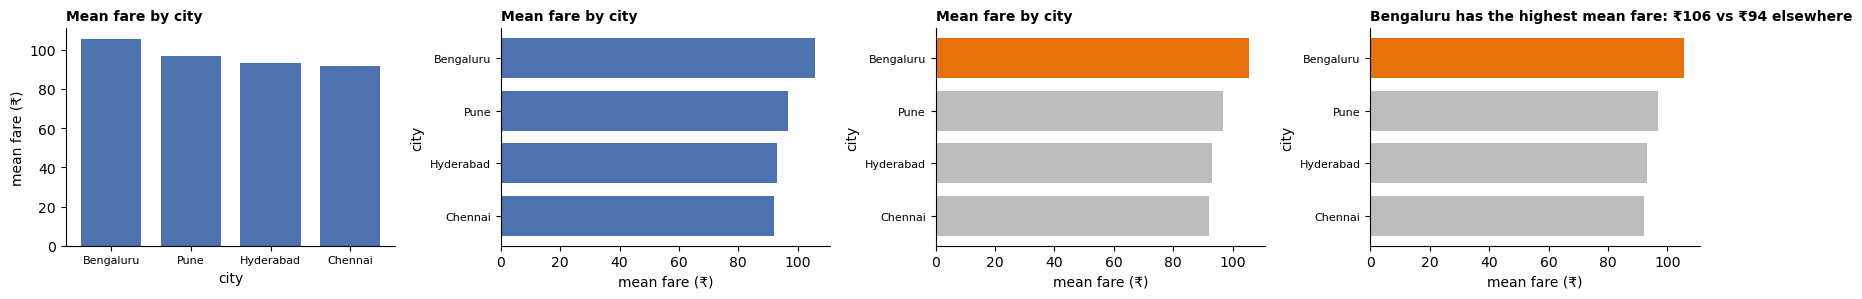

In [23]:
import copy

spec1 = copy.deepcopy(base)
# TODO edit 1: sort highest first
spec1["encoding"]["x"]["sort"] = "-y"   

spec2 = copy.deepcopy(spec1)
# TODO edit 2: swap x and y
spec2["encoding"]["x"], spec2["encoding"]["y"] = spec2["encoding"]["y"], spec2["encoding"]["x"]

spec3 = copy.deepcopy(spec2)
# TODO edit 3: highlight focus_city
spec3["encoding"]["color"] = {"condition": {"field": "city", "equal": focus_city, "value": ACCENT}, "value": GREY}  

spec4 = copy.deepcopy(spec3)
# TODO edit 4: assertion title naming the focus city
others = g.drop(focus_city).mean()
spec4["title"] = f"{focus_city} has the highest mean fare: ₹{g[focus_city]:.0f} vs ₹{others:.0f} elsewhere"  

show_specs([spec1, spec2, spec3, spec4], df, ncols=4, w=4.3, h=3.1)

assert spec_diff(base, spec1) == ["encoding.x.sort"], "edit 1 must change only the sort"
assert spec_diff(spec1, spec2) != [] and spec2["encoding"]["x"]["field"] == "fare", "edit 2: x and y must be swapped"
assert spec_diff(spec2, spec3) and all(p.startswith("encoding.color") for p in spec_diff(spec2, spec3)), "edit 3 must only add the colour encoding"
assert spec_diff(spec3, spec4) == ["title"], "edit 4 must change only the title"
assert focus_city in spec4["title"] and lint_chart(spec4) == ["OK"], f"title problems: {lint_chart(spec4)}"

### 5b · Make the answer pop out
A second question: *"Which city has the lowest cancellation rate?"* ChatViz answers with a rainbow-coloured bar chart and no annotation.
Write `bar_colors(labels, answer)` so that **only the answer bar** gets the accent colour and every other bar is grey, and write a one-line **annotation** that states the answer in words.

### Reflection: conversational chart editing

12. Compare making a chart change through natural language with changing it through a traditional visual interface. What are the main benefits and risks of the conversational approach?

13. If the user asks to ?make it clearer,? what additional information should ChatViz request before changing the chart? Suggest at least two possible interpretations.

**Answers**

12. Natural language vs. a visual interface. Conversational editing is fast and accessible: an analyst can say "sort highest first and highlight Bengaluru" without knowing where the menu lives, and several changes can be chained in one sentence. The risks are imprecision and invisibility. A phrase can be misread, an edit can silently change other parts of the spec (or drop a filter), and the user has no on-screen controls showing the current state. A traditional GUI is slower but explicit and directly reversible. The best design combines both: conversational edits applied as minimal patches (as in 5a), echoed back, with the resulting settings visible and editable as controls.

13. Make it clearer". This is under-specified, so ChatViz should ask what is unclear and for whom. Possible interpretations include: (a) emphasise the answer: highlight the key bar in an accent colour and grey the rest, and add an annotation or assertion title (as in 5b); (b) reduce clutter: remove extra colours, gridlines or legend, and sort the bars; (c) improve readability: larger fonts, horizontal bars for long labels, axis titles with units; (d) simplify the data: fewer categories, top-k plus an "Other" group, or a different chart type. A good reply offers two or three of these as quick options rather than guessing.

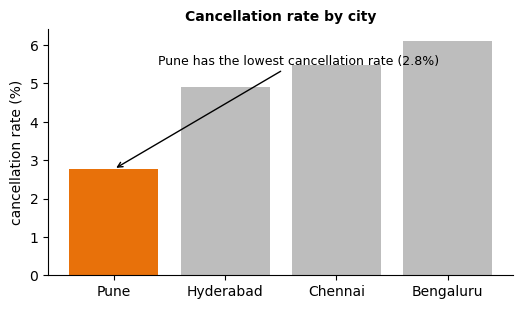

In [24]:
rate = df.groupby("city")["cancelled"].mean().sort_values() * 100
answer = rate.index[0]

def bar_colors(labels, answer):
    # TODO: a list with ACCENT for the answer and GREY for every other label
    return [ACCENT if label == answer else GREY for label in labels]

annotation = f"{answer} has the lowest cancellation rate ({rate[answer]:.1f}%)"   # TODO: one sentence stating the answer in words, with the city and its rate

colors = bar_colors(list(rate.index), answer)
assert colors.count(ACCENT) == 1 and colors.count(GREY) == len(rate) - 1
assert answer in annotation, "name the answer city in the annotation"

fig, ax = plt.subplots(figsize=(6, 3.2))
ax.bar(rate.index, rate.values, color=colors)
ax.annotate(annotation, xy=(0, rate.iloc[0]), xytext=(0.4, rate.max() * 0.9), arrowprops=dict(arrowstyle="->"), fontsize=9)
ax.set_ylabel("cancellation rate (%)"); ax.set_title("Cancellation rate by city")
plt.show()

---
## Case 6 · Post-mortem: what went wrong in the pilot? (benefits, failure modes, the nested model, mitigations)
Six incidents were reported during the pilot.

| # | Incident |
|---|---|
| I1 | The manager asked for *average* fare per city. The chart's title says "Average", but the bars are **totals**, so Bengaluru (most rides) wins. |
| I2 | After *"only 2025"*, the follow-up *"what about cancellations?"* was drawn for **all years**, with no warning. |
| I3 | A chart was drawn of `driver_score`, a column that **does not exist**; the tool quietly filled it with random numbers. |
| I4 | A **line** was drawn connecting Auto, Mini, Sedan and Bike for *"compare average fare by vehicle type"*. |
| I5 | Bars comparing cancellation rates of 4.1 % and 4.4 % started the y-axis at 4 %, making one city look **twice as bad**. |
| I6 | The caption under a scatter plot read *"Surge pricing **causes** cancellations."* |

### 6a · Classify
**(i)** Label each incident with exactly one failure mode from `FAILURE_MODES`.
**(ii)** Place each statement in the right level of **Munzner's nested model** (`"domain"`, `"abstraction"`, `"idiom"`, `"algorithm"`).
**(iii)** Pick the best **mitigation** for each situation from `MITIGATIONS`.

* **L1.** The code crashes with a `KeyError`.
* **L2.** The tool answers a *trend* question when the analyst actually needed to *compare two groups*.
* **L3.** A 12-slice pie is used to compare ride counts.
* **L4.** Finance defines "revenue" net of driver incentives, but the tool uses gross fares.

Mitigation situations: **M1** — follow-ups silently drop filters (I2). **M2** — the tool keeps choosing pies and truncated axes (I4/I5). **M3** — a wrong aggregation slips through while the chart runs fine (I1). **M4** — a chart is about to go into the **board report**.

In [25]:
FAILURE_MODES = ["hallucinated field", "wrong aggregation / filter", "wrong chart for the task", "misleading design", "context drift", "over-confident narrative"]
LEVELS = ["domain", "abstraction", "idiom", "algorithm"]
MITIGATIONS = ["echo the interpretation", "make choices editable", "validate before showing", "keep the spec / code", "constrain the design", "human review for decisions"]

In [26]:
failure_mode = {
    "I1": "wrong aggregation / filter",   # sum drawn instead of mean
    "I2": "context drift",                # the 2025 filter was lost between turns
    "I3": "hallucinated field",           # driver_score does not exist
    "I4": "wrong chart for the task",     # a line implies order/continuity between nominal categories
    "I5": "misleading design",            # truncated bar axis exaggerates a 0.3-point gap
    "I6": "over-confident narrative",     # a scatter shows association, not causation
}
nested_level = {
    "L1": "algorithm",     # implementation bug: the code itself fails
    "L2": "abstraction",   # wrong task abstraction (trend vs compare)
    "L3": "idiom",         # wrong visual encoding for a comparison
    "L4": "domain",        # misunderstands the business meaning of "revenue"
}
mitigation = {
    "M1": "echo the interpretation",      # say "showing cancellations, all years" so the dropped filter is visible
    "M2": "constrain the design",         # ban pies for comparison, force zero-based bar axes
    "M3": "validate before showing",      # sanity check the aggregate against the user's intent
    "M4": "human review for decisions",   # an analyst signs off before a board report
}

assert all(v in FAILURE_MODES for v in failure_mode.values()), "failure_mode: choose from FAILURE_MODES"
assert all(v in LEVELS for v in nested_level.values()), "nested_level: choose from LEVELS"
assert all(v in MITIGATIONS for v in mitigation.values()), "mitigation: choose from MITIGATIONS"

### 6b · Your recommendation
Incident **I1** looked perfectly fine on screen and was only noticed because a manager happened to check the numbers. In two or three sentences: **which level of the nested model do the costliest errors live at, why are they dangerous,
and what should SwiftBite-style rollout rules require before ChatViz goes to every analyst?** *(Use RideNow in your answer.)*

### Reflection: rollout priorities and safeguards

14. What safeguards are needed when a visualization could expose sensitive operational information, such as driver performance or neighborhood-level demand?

15. After auditing ChatViz, what is the single most important improvement you would prioritize, and why?

**Answers**

14. Safeguards for sensitive data. ChatViz should respect role-based access, so an analyst can query only the fields and granularity their role allows (e.g. driver-level ratings only for driver-ops leads). It should aggregate by default and enforce minimum group sizes (k-anonymity style), so a "neighbourhood × hour" chart cannot single out one driver or rider. Personal identifiers should be masked, every query logged for audit, and charts with driver-level or fine-grained demand data should get a warning or reviewer approval before they can be exported or shared.

15. Top priority. I would prioritise validate-and-echo before showing: run the field and intent-sanity checks on every spec, and always show the interpretation (measure, aggregation, filters) next to the chart. The most damaging pilot incidents (I1 wrong aggregation, I2 dropped filter, I3 invented field) all produced charts that looked fine. This one change turns silent errors into either a blocked spec or an interpretation the analyst can see is wrong, and it costs far less than retraining the model.

In [27]:
final_recommendation = (
    "At RideNow the costliest errors live at the upper levels of the nested model (domain and abstraction), "
    "like I1, where ChatViz misread 'average' as 'total': the code runs, the chart looks polished and the title even says "
    "'Average', so nothing crashes and the error only surfaces if someone re-checks the numbers, while every level below "
    "inherits the mistake. Before ChatViz goes to every analyst, rollout rules should require that it echoes its "
    "interpretation (measure, aggregation, filters) on every chart, runs schema/field/sanity validation against the "
    "user's intent before showing anything, keeps the spec and code inspectable, and that any chart used for a "
    "business decision or board report is reviewed by a human analyst."
)
print(final_recommendation)

At RideNow the costliest errors live at the upper levels of the nested model (domain and abstraction), like I1, where ChatViz misread 'average' as 'total': the code runs, the chart looks polished and the title even says 'Average', so nothing crashes and the error only surfaces if someone re-checks the numbers, while every level below inherits the mistake. Before ChatViz goes to every analyst, rollout rules should require that it echoes its interpretation (measure, aggregation, filters) on every chart, runs schema/field/sanity validation against the user's intent before showing anything, keeps the spec and code inspectable, and that any chart used for a business decision or board report is reviewed by a human analyst.


---
### Before you finish
Run the cell below to see whether any answer has been left blank.

In [28]:
_required = ["abstract_tasks", "ambiguity_strategy", "turn_types", "transitions", "session_6_turns", "session_6_better", "turns_below_half",
             "prompt_fix", "exact_match_rate", "execution_accuracy", "component_acc", "ea_not_em", "annotation",
             "failure_mode", "nested_level", "mitigation", "final_recommendation"]
_blank = []
for _name in _required:
    _v = globals().get(_name)
    if _v is None or (isinstance(_v, str) and not _v.strip()) or (isinstance(_v, dict) and any(x is None for x in _v.values())):
        _blank.append(_name)
print("All answers filled in." if not _blank else "Still blank: " + ", ".join(_blank))

All answers filled in.
